# TD/TP 1 — Binary classification with a neural network

**IMT · Introduction to Machine Learning · Google Colab**  

**Learning objectives:** prepare labeled data; compare linear and non-linear classifiers; build/train/evaluate an MLP; visualize the decision boundary.

### How to use this notebook
1. Read the questions, run the prepared cells in order, and complete every **✍️ TODO** cell yourself.
2. The data preparation and plotting helpers are supplied so you can focus on machine learning.
3. If you get stuck, discuss your approach with a classmate before consulting the instructor.
4. You will receive the complete solution notebook after the collective correction.

**Environment:** Google Colab → Runtime → Run all

## Scenario: can a neural network learn a curved boundary?

We use the **two-moons** dataset: two intertwined groups of points. Each point has two coordinates; the target is class 0 or 1. A linear separator has difficulty here, so this is a useful test for non-linear activations.

**Questions to keep in mind:** What are the model, loss, and optimizer? Why must we evaluate on unseen data?

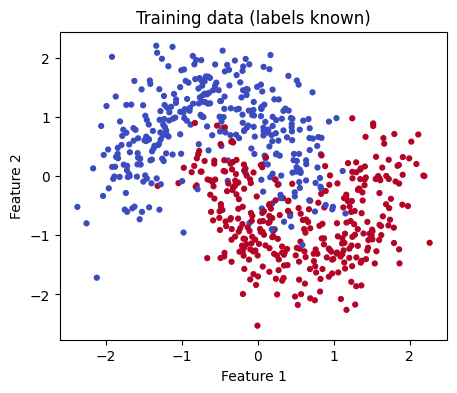

Training samples: 675 | Test samples: 225


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)

X, y = make_moons(n_samples=900, noise=0.25, random_state=SEED)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED
)
scaler = StandardScaler().fit(X_train)  # IMPORTANT: fit on training data only
X_train, X_test = scaler.transform(X_train), scaler.transform(X_test)
xtr = torch.tensor(X_train, dtype=torch.float32)
ytr = torch.tensor(y_train[:, None], dtype=torch.float32)
xte = torch.tensor(X_test, dtype=torch.float32)
yte = torch.tensor(y_test[:, None], dtype=torch.float32)
train_loader = DataLoader(TensorDataset(xtr, ytr), batch_size=64, shuffle=True)

fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='coolwarm', s=12)
ax.set(title='Training data (labels known)', xlabel='Feature 1', ylabel='Feature 2')
plt.show()
print('Training samples:', len(X_train), '| Test samples:', len(X_test))

## 1. Establish a linear baseline

Before using deep learning, fit a simple **logistic regression** classifier. This is a linear decision boundary. Compare its test accuracy with what you obtain later.

In [2]:
baseline = LogisticRegression().fit(X_train, y_train)
baseline_accuracy = accuracy_score(y_test, baseline.predict(X_test))
print(f'Linear baseline test accuracy: {baseline_accuracy:.3f}')

Linear baseline test accuracy: 0.893


## 2. ✍️ TODO — define the hypothesis (model)

Implement `make_model()` using `torch.nn.Sequential`:

- Input: 2 features
- Hidden layer: 16 neurons + ReLU
- Hidden layer: 16 neurons + ReLU
- Output: **1 logit** (no final sigmoid; the loss applies it internally)

**Checkpoint:** `make_model()(xtr[:5]).shape` should be `(5, 1)`.

In [3]:
def make_model():
    model = nn.Sequential(
        nn.Linear(2, 16), nn.ReLU(),
        nn.Linear(16, 16), nn.ReLU(),
        nn.Linear(16, 1), nn.Sigmoid()
    )
    return model

model = make_model()
assert model(xtr[:5]).shape == (5, 1)
print(model)

Sequential(
  (0): Linear(in_features=2, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=16, bias=True)
  (3): ReLU()
  (4): Linear(in_features=16, out_features=1, bias=True)
  (5): Sigmoid()
)


## 3. ✍️ TODO — choose the loss and optimizer

For binary classification, use **binary cross-entropy with logits** (`BCEWithLogitsLoss`). Use Adam with learning rate `0.01`.

**Question:** Why would mean-squared error be less natural for a probability/classification problem?

> **Instructor note / expected reasoning:** BCE uses a Bernoulli likelihood and strongly penalizes confident mistakes. `BCEWithLogitsLoss` is also numerically stable compared with explicit sigmoid + log.

In [4]:
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
print(type(criterion).__name__, type(optimizer).__name__)

BCEWithLogitsLoss Adam


## 4. ✍️ TODO — implement the training loop

Fill in `train_one_epoch` using this order:

1. Clear old gradients.
2. Compute the model output (logits).
3. Compute loss against ground-truth labels.
4. Backpropagate.
5. Update the parameters.

This is exactly the **forward pass → loss → backward pass → optimizer step** loop from the slides.

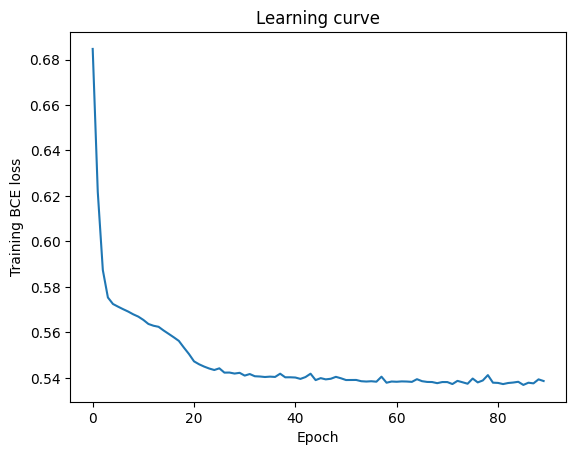

In [5]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss = 0.0
    for xb, yb in loader:
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(xb)
    return total_loss / len(loader.dataset)

history = []
for epoch in range(90):
    history.append(train_one_epoch(model, train_loader, criterion, optimizer))

plt.plot(history)
plt.xlabel('Epoch'); plt.ylabel('Training BCE loss'); plt.title('Learning curve')
plt.show()

## 5. ✍️ TODO — convert logits into class predictions

Your network outputs **logits**, not probabilities. Apply `torch.sigmoid` and classify using the threshold `0.5`. Report test accuracy and plot a confusion matrix.

**Checkpoint:** probabilities must lie between 0 and 1.

Neural network test accuracy: 0.498 (linear: 0.893)


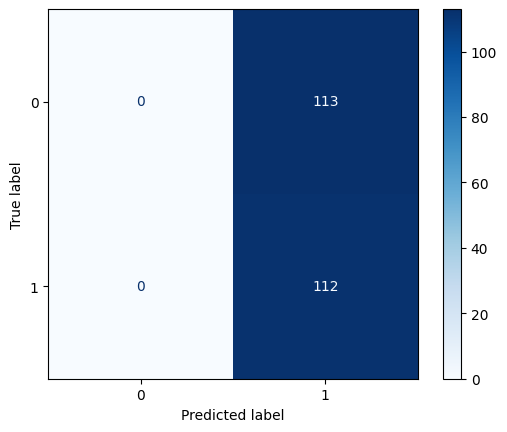

In [6]:
model.eval()
with torch.no_grad():
    test_logits = model(xte)
    test_prob = torch.sigmoid(test_logits).cpu().numpy().ravel()
    test_pred = (test_prob >= 0.5).astype(int)

assert test_prob.min() >= 0 and test_prob.max() <= 1
nn_accuracy = accuracy_score(y_test, test_pred)
print(f'Neural network test accuracy: {nn_accuracy:.3f} (linear: {baseline_accuracy:.3f})')
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, cmap='Blues')
plt.show()

## 6. Decision boundaries (provided visualization)

The figure makes the difference between the **linear hypothesis** and the **non-linear hypothesis** visible.

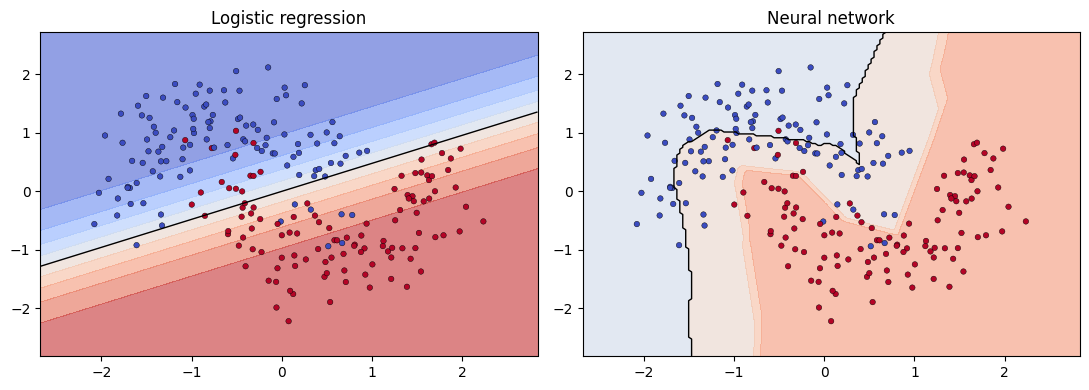

In [7]:
def plot_boundary(ax, predict_fn, title):
    grid_x, grid_y = np.meshgrid(
        np.linspace(X_test[:, 0].min()-0.6, X_test[:, 0].max()+0.6, 170),
        np.linspace(X_test[:, 1].min()-0.6, X_test[:, 1].max()+0.6, 170),
    )
    grid = np.c_[grid_x.ravel(), grid_y.ravel()]
    probs = predict_fn(grid).reshape(grid_x.shape)
    ax.contourf(grid_x, grid_y, probs, levels=np.linspace(0,1,11), cmap='coolwarm', alpha=.6)
    ax.contour(grid_x, grid_y, probs, levels=[.5], colors='k', linewidths=1)
    ax.scatter(X_test[:,0], X_test[:,1], c=y_test, cmap='coolwarm', edgecolor='k', linewidth=.3, s=16)
    ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(11,4))
plot_boundary(axes[0], lambda z: baseline.predict_proba(z)[:,1], 'Logistic regression')
def predict_nn(z):
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(torch.tensor(z, dtype=torch.float32))).numpy().ravel()
plot_boundary(axes[1], predict_nn, 'Neural network')
plt.tight_layout(); plt.show()

### Discussion / optional challenge

1. What happens if you remove **both ReLU activations**? Why?
2. What changes if the learning rate is `0.0001` versus `0.1`?
3. Why is fitting the feature scaler on the whole dataset considered data leakage?
4. **Challenge:** retrain with only 2 hidden neurons; visualize the new boundary.

**Takeaway:** The model learns parameters by minimizing a task-specific loss; non-linear layers enable curved boundaries.